# IPL Match Analytics: Exploratory Data Analysis

This notebook answers questions using the cleaned CSV files. It calculates summaries from the data rather than typing results into the notebook.

We use `calendar_year` for year-by-year analysis because the provided `season` labels do not consistently match the match dates. Missing statistics are left missing, and matches with no winner are excluded from winner-rate calculations.

**Questions:** How do match counts change over time? Which teams win most often? Who leads the player statistics? Which venues host the most matches? How are toss decisions and win results related?

**Important:** The match table has one row per match. Player and delivery tables have different row granularities, so use the table appropriate to the question.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")

possible_roots = [Path.cwd(), Path.cwd().parent]
project_root = next(
    root for root in possible_roots
    if (root / "data" / "processed" / "ipl_matches_summary.csv").exists()
)
processed_dir = project_root / "data" / "processed"

matches = pd.read_csv(processed_dir / "ipl_matches_summary.csv", parse_dates=["date"])
balls = pd.read_csv(
    processed_dir / "ipl_ball_by_ball_processed.csv",
    parse_dates=["date"],
    low_memory=False,
)
players = pd.read_csv(processed_dir / "ipl_player_profiles.csv")

# Use the match date, not the inconsistent source season label, for calendar-year charts.
matches["calendar_year"] = matches["date"].dt.year
balls["calendar_year"] = balls["date"].dt.year

print(f"Project folder: {project_root}")
print(f"Matches: {matches.shape[0]:,} rows x {matches.shape[1]} columns")
print(f"Deliveries: {balls.shape[0]:,} rows x {balls.shape[1]} columns")
print(f"Player profiles: {players.shape[0]:,} rows x {players.shape[1]} columns")
print("Match table preview:")
display(matches.head())

Project folder: C:\Users\abhay\Downloads\archive (2)
Matches: 1,243 rows x 60 columns
Deliveries: 295,732 rows x 109 columns
Player profiles: 811 rows x 41 columns
Match table preview:


,match_id,season,date,venue,city,team1,team2,toss_winner,toss_decision,outcome_winner,...,venue_matches_prior,venue_team1_win_pct,venue_team2_win_pct,venue_avg_first_innings_score,venue_chase_win_pct,team1_is_toss_winner,toss_decision_field,team1_won,toss_winner_is_winner,calendar_year
0,335982,2007,2008-04-18,M Chinnaswamy Stadium,Bangalore,Royal Challengers Bengaluru,Kolkata Knight Riders,Royal Challengers Bengaluru,field,Kolkata Knight Riders,...,0,0.5,0.5,160.0,0.5,True,1,False,False,2008
1,335983,2007,2008-04-19,Punjab Cricket Association IS Bindra Stadium,Chandigarh,Punjab Kings,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,...,0,0.5,0.5,160.0,0.5,False,0,False,True,2008
2,335984,2007,2008-04-19,Arun Jaitley Stadium,Delhi,Delhi Capitals,Rajasthan Royals,Rajasthan Royals,bat,Delhi Capitals,...,0,0.5,0.5,160.0,0.5,False,0,True,False,2008
3,335985,2007,2008-04-20,Wankhede Stadium,Mumbai,Mumbai Indians,Royal Challengers Bengaluru,Mumbai Indians,bat,Royal Challengers Bengaluru,...,0,0.5,0.5,160.0,0.5,True,0,False,False,2008
4,335986,2007,2008-04-20,Eden Gardens,Kolkata,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,...,0,0.5,0.5,160.0,0.5,False,0,True,False,2008


## 1. Data Quality Snapshot

These checks show the dimensions, repeated rows, and most-missing columns. A missing value can mean that a statistic does not apply (for example, a bowling metric for a player with no bowling record), so we inspect it instead of replacing every blank with zero.

In [2]:
tables = {
    "Matches": matches,
    "Deliveries": balls,
    "Players": players,
}

quality_summary = []
for table_name, table in tables.items():
    quality_summary.append(
        {
            "table": table_name,
            "rows": len(table),
            "columns": table.shape[1],
            "exact_duplicate_rows": int(table.duplicated().sum()),
            "cells_missing": int(table.isna().sum().sum()),
        }
    )

display(pd.DataFrame(quality_summary))

for table_name, table in tables.items():
    missing = table.isna().sum().sort_values(ascending=False)
    missing = missing[missing > 0].head(8)
    print(f"\nMost-missing columns in {table_name}:")
    display((missing / len(table) * 100).round(1).rename("missing_percent").to_frame())

,table,rows,columns,exact_duplicate_rows,cells_missing
0,Matches,1243,60,0,2624
1,Deliveries,295732,109,0,3993059
2,Players,811,41,0,2920



Most-missing columns in Matches:


,missing_percent
outcome_method,98.1
outcome_result,98.0
match_number,6.0
outcome_winner,2.0
team1_won,2.0
toss_winner_is_winner,2.0
reserve_umpire,1.9
player_of_match,0.7



Most-missing columns in Deliveries:


,missing_percent
replacement_role,100.0
fielder2_name,99.8
drs_type,99.8
replacement_out_player,99.8
replacement_in_player,99.8
replacement_reason,99.8
drs_by,99.7
drs_decision,99.7



Most-missing columns in Players:


,missing_percent
field_pos,86.3
powerplay_strike_rate,43.0
powerplay_economy,42.9
death_overs_economy,39.7
bowling_strike_rate,39.5
bowling_average,39.5
bowling_economy,28.9
middle_strike_rate,20.1


## 2. Match, Team, and Venue Results

We use the match table for match-level questions. A resolved match is one with a recorded winner; tied and no-result matches stay in the dataset but are excluded from win-rate denominators. `outcome_by_runs` and `outcome_by_wickets` tell us the recorded winning margin.

In [3]:
resolved_matches = matches.loc[matches["outcome_winner"].notna()].copy()
resolved_matches = resolved_matches.loc[resolved_matches["outcome_winner"].astype("string").str.strip().ne("")]

match_counts_by_year = matches.groupby("calendar_year").size().rename("matches")
team_appearances = pd.concat([resolved_matches["team1"], resolved_matches["team2"]]).value_counts()
team_wins = resolved_matches["outcome_winner"].value_counts()
team_results = pd.DataFrame({"resolved_matches": team_appearances, "wins": team_wins}).fillna(0)
team_results["win_percent"] = team_results["wins"] / team_results["resolved_matches"] * 100
team_results = team_results.sort_values("wins", ascending=False)

win_by_runs = int((pd.to_numeric(resolved_matches["outcome_by_runs"], errors="coerce") > 0).sum())
win_by_wickets = int((pd.to_numeric(resolved_matches["outcome_by_wickets"], errors="coerce") > 0).sum())
player_of_match_leaders = matches["player_of_match"].dropna().value_counts().head(10)
venue_counts = matches["venue"].value_counts().head(12)

print("Matches by calendar year:")
display(match_counts_by_year.to_frame())
print("Teams with the most recorded wins:")
display(team_results.head(10).round({"win_percent": 1}))
print(f"Wins by runs: {win_by_runs}; wins by wickets: {win_by_wickets}")
print("Most Player of the Match awards:")
display(player_of_match_leaders.rename("awards").to_frame())
print("Most frequently used venues:")
display(venue_counts.rename("matches").to_frame())

Matches by calendar year:


,matches
calendar_year,
2008,58
2009,57
2010,60
2011,73
2012,74
2013,76
2014,60
2015,59
2016,60


Teams with the most recorded wins:


,resolved_matches,wins,win_percent
Mumbai Indians,287,155,54.0
Chennai Super Kings,264,148,56.1
Royal Challengers Bengaluru,280,143,51.1
Kolkata Knight Riders,271,140,51.7
Punjab Kings,271,126,46.5
Delhi Capitals,272,125,46.0
Rajasthan Royals,245,123,50.2
Sunrisers Hyderabad,206,102,49.5
Gujarat Titans,77,47,61.0
Lucknow Super Giants,70,34,48.6


Wins by runs: 558; wins by wickets: 660
Most Player of the Match awards:


,awards
player_of_match,
AB de Villiers,25
CH Gayle,22
V Kohli,22
RG Sharma,21
MS Dhoni,18
DA Warner,18
SP Narine,18
RA Jadeja,17
KL Rahul,17


Most frequently used venues:


,matches
venue,
Wankhede Stadium,132
Eden Gardens,107
M Chinnaswamy Stadium,104
Arun Jaitley Stadium,104
MA Chidambaram Stadium,98
Rajiv Gandhi International Stadium,90
Sawai Mansingh Stadium,68
Punjab Cricket Association IS Bindra Stadium,61
Narendra Modi Stadium,53


## 3. Player Performance

These are career totals from the supplied player table, not season-by-season statistics. Strike rates and economy figures can look extreme for players with very few balls, so raw leaderboard results should be interpreted with sample size in mind.

In [4]:
player_numeric_columns = ["runs_scored", "fours", "sixes", "wickets", "matches_selected"]
for column_name in player_numeric_columns:
    players[column_name] = pd.to_numeric(players[column_name], errors="coerce")

print("Top run scorers:")
display(players.nlargest(10, "runs_scored")[["player_name", "runs_scored", "matches_selected"]])
print("Most fours:")
display(players.nlargest(10, "fours")[["player_name", "fours", "matches_selected"]])
print("Most sixes:")
display(players.nlargest(10, "sixes")[["player_name", "sixes", "matches_selected"]])
print("Leading wicket takers:")
display(players.nlargest(10, "wickets")[["player_name", "wickets", "matches_selected"]])

Top run scorers:


,player_name,runs_scored,matches_selected
0,V Kohli,9336,282
1,RG Sharma,7329,281
2,S Dhawan,6769,222
3,DA Warner,6565,184
4,KL Rahul,5815,160
5,SK Raina,5528,204
6,MS Dhoni,5439,277
7,AM Rahane,5367,212
8,SV Samson,5181,190
9,AB de Villiers,5162,183


Most fours:


,player_name,fours,matches_selected
0,V Kohli,845,282
2,S Dhawan,768,222
3,DA Warner,663,184
1,RG Sharma,661,281
7,AM Rahane,540,212
4,KL Rahul,508,160
5,SK Raina,506,204
19,G Gambhir,492,154
16,SA Yadav,482,179
11,RV Uthappa,481,205


Most sixes:


,player_name,sixes,matches_selected
10,CH Gayle,357,141
1,RG Sharma,324,281
0,V Kohli,317,282
6,MS Dhoni,264,277
9,AB de Villiers,251,183
8,SV Samson,243,190
4,KL Rahul,239,160
3,DA Warner,236,184
26,KA Pollard,223,189
39,AD Russell,223,139


Leading wicket takers:


,player_name,wickets,matches_selected
437,YS Chahal,233,189
189,B Kumar,226,206
68,SP Narine,207,201
146,PP Chawla,192,192
128,R Ashwin,187,219
369,JJ Bumrah,187,158
78,DJ Bravo,183,160
24,RA Jadeja,180,267
145,Rashid Khan,179,153
183,A Mishra,174,162


## 4. Toss and Innings Results

A team may win the toss but lose the match. We calculate the observed toss-winner win rate by the recorded toss decision; this is an association in historical data, not proof of cause. The innings score chart uses first-innings totals from the match summary.

In [5]:
toss_table = resolved_matches.dropna(subset=["toss_decision", "toss_winner_is_winner"]).copy()
toss_table["toss_winner_won"] = toss_table["toss_winner_is_winner"].astype(bool)
toss_rates = (toss_table.groupby("toss_decision", observed=True)["toss_winner_won"].mean() * 100).round(1)

first_innings_scores = pd.to_numeric(matches["inn1_total_runs"], errors="coerce")
print("Toss-winning team's match-win percentage by toss decision:")
display(toss_rates.rename("toss_winner_win_percent").to_frame())
print("First-innings score summary:")
display(first_innings_scores.describe().round(1).to_frame("runs"))
print(f"Resolved matches included in team win rates: {len(resolved_matches):,} of {len(matches):,} total matches")

Toss-winning team's match-win percentage by toss decision:


,toss_winner_win_percent
toss_decision,
bat,45.3
field,54.7


First-innings score summary:


,runs
count,1243.0
mean,168.6
std,34.1
min,25.0
25%,148.0
50%,168.0
75%,190.0
max,287.0


Resolved matches included in team win rates: 1,218 of 1,243 total matches


## 5. Visual Exploration

The line and bar charts compare counts across time and teams. The histogram shows the spread of first-innings scores; the box plot compares score distributions at frequently used venues. The heatmap shows the percentage of tosses won/lost as matches by toss decision.

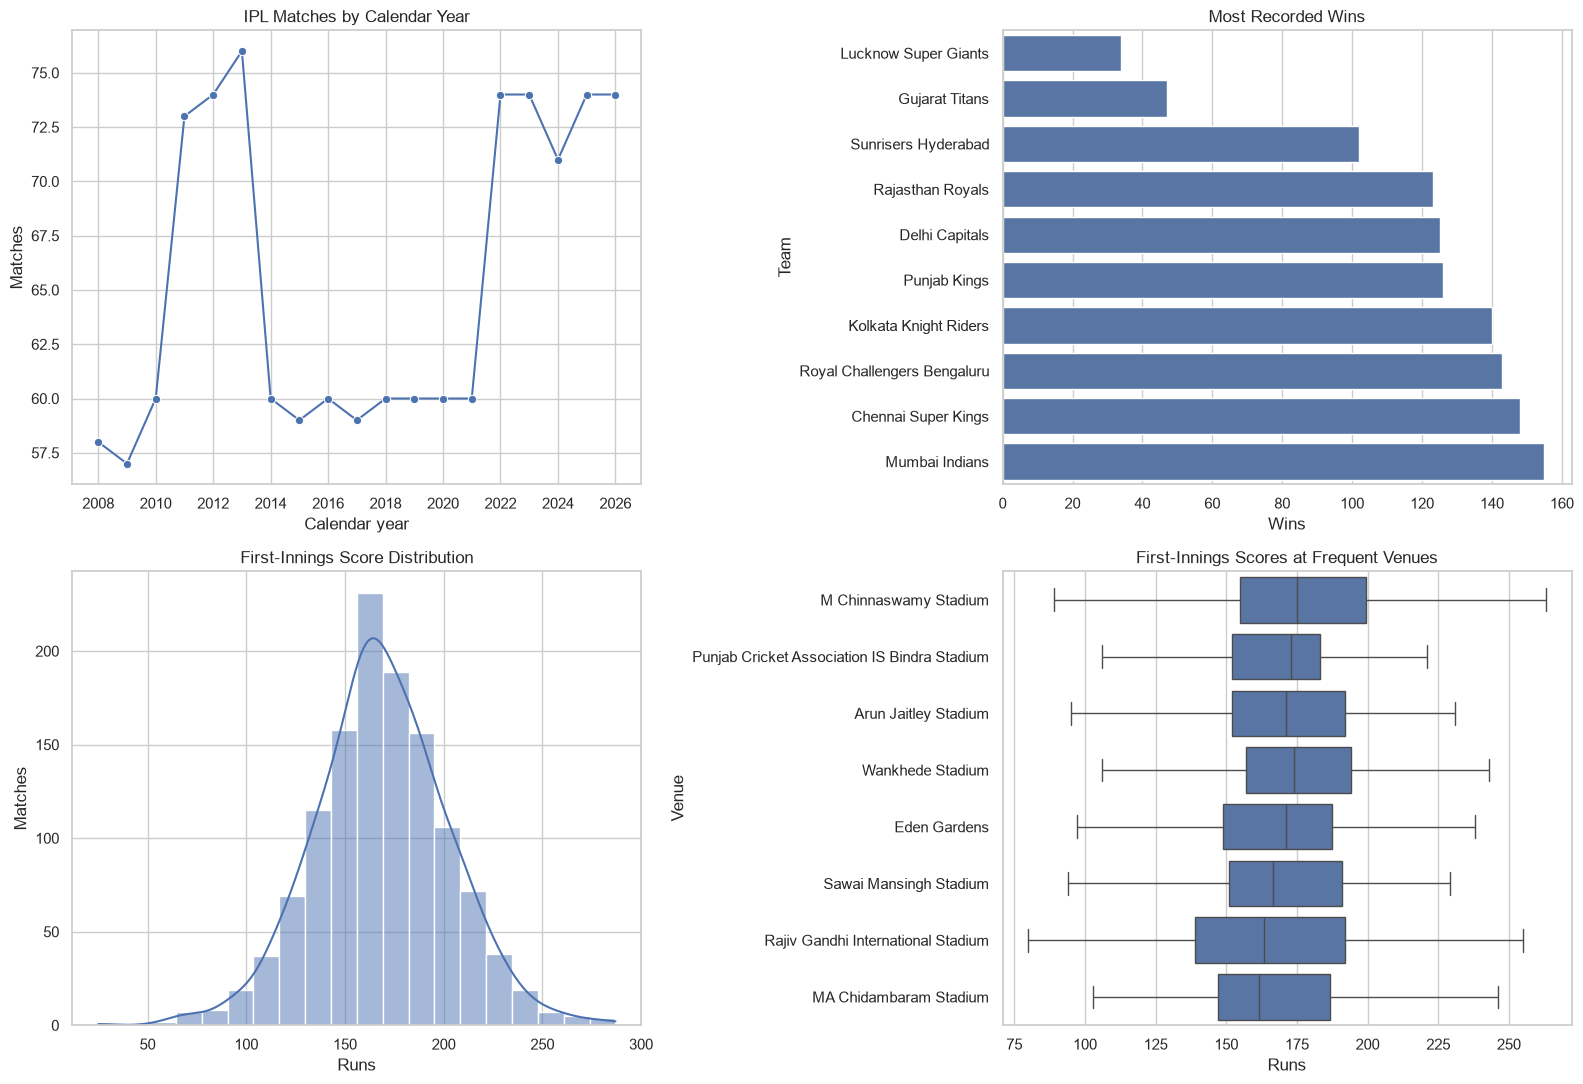

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

sns.lineplot(x=match_counts_by_year.index, y=match_counts_by_year.values, marker="o", ax=axes[0, 0])
axes[0, 0].set(title="IPL Matches by Calendar Year", xlabel="Calendar year", ylabel="Matches")
axes[0, 0].set_xticks(match_counts_by_year.index[::2])

team_plot_data = team_results.head(10).sort_values("wins")
sns.barplot(data=team_plot_data, x="wins", y=team_plot_data.index, ax=axes[0, 1], color=sns.color_palette()[0])
axes[0, 1].set(title="Most Recorded Wins", xlabel="Wins", ylabel="Team")

sns.histplot(first_innings_scores.dropna(), bins=20, kde=True, ax=axes[1, 0])
axes[1, 0].set(title="First-Innings Score Distribution", xlabel="Runs", ylabel="Matches")

common_venues = matches["venue"].value_counts().head(8).index
venue_scores = matches.loc[matches["venue"].isin(common_venues)].copy()
venue_scores["inn1_total_runs"] = pd.to_numeric(venue_scores["inn1_total_runs"], errors="coerce")
sns.boxplot(data=venue_scores, x="inn1_total_runs", y="venue", showfliers=False, ax=axes[1, 1])
axes[1, 1].set(title="First-Innings Scores at Frequent Venues", xlabel="Runs", ylabel="Venue")

fig.tight_layout()
display(fig)
plt.close(fig)

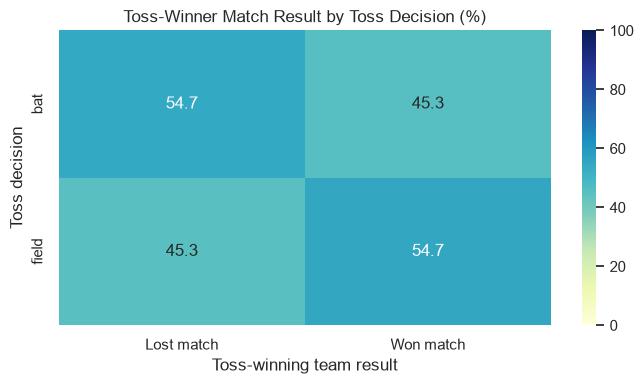

In [7]:
toss_heatmap = pd.crosstab(
    toss_table["toss_decision"],
    toss_table["toss_winner_won"].map({True: "Won match", False: "Lost match"}),
    normalize="index",
) * 100

heatmap_figure, heatmap_axis = plt.subplots(figsize=(7, 4))
sns.heatmap(
    toss_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    ax=heatmap_axis,
)
heatmap_axis.set_title("Toss-Winner Match Result by Toss Decision (%)")
heatmap_axis.set_xlabel("Toss-winning team result")
heatmap_axis.set_ylabel("Toss decision")
heatmap_figure.tight_layout()
display(heatmap_figure)
plt.close(heatmap_figure)

## 6. What the Data Says and What It Cannot Say

The next cell prints a few observations from the calculated tables. These are descriptive findings, not causal claims. The dataset currently ends on the latest date shown in the loaded match file; conclusions about the latest season may change if more matches are added.

In [8]:
top_team = team_results.index[0]
top_run_scorer = players.nlargest(1, "runs_scored").iloc[0]
top_wicket_taker = players.nlargest(1, "wickets").iloc[0]
top_venue = venue_counts.index[0]
top_award_player = player_of_match_leaders.index[0] if not player_of_match_leaders.empty else "No recorded awards"
latest_match_date = matches["date"].max().date()

print(f"Most recorded team wins: {top_team} ({int(team_results.loc[top_team, 'wins'])}).")
print(f"Most runs in the player table: {top_run_scorer['player_name']} ({int(top_run_scorer['runs_scored']):,}).")
print(f"Most wickets in the player table: {top_wicket_taker['player_name']} ({int(top_wicket_taker['wickets']):,}).")
print(f"Most frequently hosted venue: {top_venue} ({int(venue_counts.iloc[0])} matches).")
print(f"Most Player of the Match awards: {top_award_player} ({int(player_of_match_leaders.iloc[0]) if len(player_of_match_leaders) else 0}).")
print(f"Winning margins in resolved matches: {win_by_runs:,} by runs and {win_by_wickets:,} by wickets.")
print(f"Latest match date in this dataset: {latest_match_date}.")

print("\nInterpretation limits:")
print("- Toss percentages describe this historical sample; they do not establish that a toss decision causes a win.")
print("- Player totals combine seasons, and small-sample rate statistics can be misleading.")
print("- Season labels are inconsistent with dates; use calendar_year for timeline analysis.")
print("- A future prediction model must exclude match outcomes and final-state fields from its input features.")

Most recorded team wins: Mumbai Indians (155).
Most runs in the player table: V Kohli (9,336).
Most wickets in the player table: YS Chahal (233).
Most frequently hosted venue: Wankhede Stadium (132 matches).
Most Player of the Match awards: AB de Villiers (25).
Winning margins in resolved matches: 558 by runs and 660 by wickets.
Latest match date in this dataset: 2026-05-31.

Interpretation limits:
- Toss percentages describe this historical sample; they do not establish that a toss decision causes a win.
- Player totals combine seasons, and small-sample rate statistics can be misleading.
- Season labels are inconsistent with dates; use calendar_year for timeline analysis.
- A future prediction model must exclude match outcomes and final-state fields from its input features.
